AMT_INCOME_TOTAL    391.559654
AMT_ANNUITY           1.579777
AMT_CREDIT            1.234779
AGE_YEARS             0.115673
dtype: float64


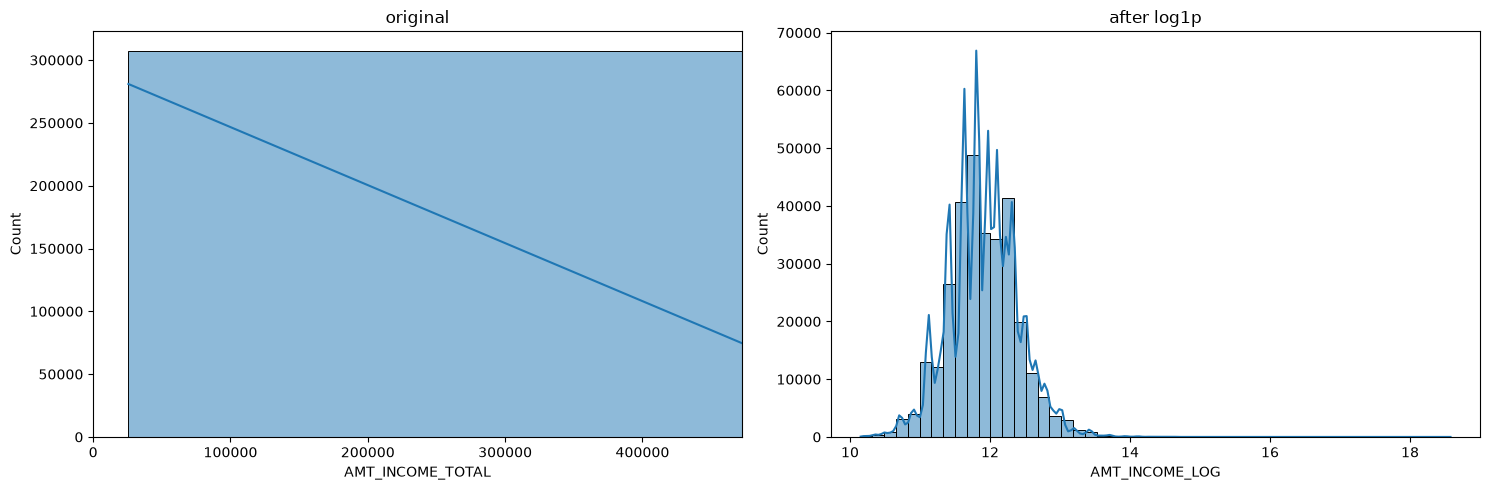

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_parquet('../data/optimized_cleaned.parquet')# .. значит выйти из папки наверх 
numeric_cols = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AGE_YEARS']
skew_values = df[numeric_cols].skew().sort_values(ascending = False)
print(skew_values)
fig,axes = plt.subplots(1,2,figsize=(15,5))

sns.histplot(df['AMT_INCOME_TOTAL'],bins=50,kde=True,ax = axes[0])
axes[0].set_title("original")
axes[0].set_xlim(0,df['AMT_INCOME_TOTAL'].quantile(0.99))

df['AMT_INCOME_LOG'] = np.log1p(df['AMT_INCOME_TOTAL'])# = log(x + 1)
sns.histplot(df['AMT_INCOME_LOG'],bins=50,kde=True,ax = axes[1])
axes[1].set_title("after log1p")

plt.tight_layout()
plt.show()








Параметр AMT_INCOME_TOTAL очень сильно скошен вправо,поэтому на левом графике один сплошоной прямоугольник.После логарифмизации эталонный график. 
AMT_ANNUITY и AMT_CREDIT тоже превышают норму (>1) скошенности 

In [8]:
from scipy import stats

group_0 = df[df['TARGET'] == 0]
group_1 = df[df['TARGET'] == 1]# дефолтники
#проверяем гипотезу о том что возраст различается у дефолтников и недефолтников
stat_age,p_value_age = stats.ttest_ind(
    group_0['AGE_YEARS'].dropna(),
    group_1['AGE_YEARS'].dropna(),
    equal_var = False
)

print(f"p-value: {p_value_age:.10e}")
if p_value_age < 0.05:
    print("Отвергаем H0. Возраст статистически значимо различается у двух групп.")
else:
    print("Принимаем H0. Возраст не влияет.")

#проверяем гипотезу о том что доходы различаются у дефолтников и недефолтников
stat_age,p_value_inc = stats.mannwhitneyu(
    group_0['AGE_YEARS'].dropna(),
    group_1['AGE_YEARS'].dropna()
)

print(f"p-value: {p_value_inc:.10e}")
if p_value_inc < 0.05:
    print("Отвергаем H0. Доходы статистически различаются.")
else:
    print("Принимаем H0. Доходы двух групп одинаковы.")



p-value: 0.0000000000e+00
Отвергаем H0. Возраст статистически значимо различается у двух групп.
p-value: 0.0000000000e+00
Отвергаем H0. Доходы статистически различаются.
